In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)


In [2]:
POLLUTANTS = ["pm25", "pm10"]
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
TEST_FRACTION = 0.2

WEATHER_MODES = {
    "same_day": "same-day observed weather (nowcast / association)",
    "t_minus_1": "weather from day t-1 (true forecast)",
}


In [3]:
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")


In [4]:
def get_weather_cols(df):
    return [
        col for col in df.columns
        if (col.startswith(("temperature", "relative_humidity", "dew_point",
                            "apparent_temperature", "pressure", "surface_pressure",
                            "precipitation", "rain_sum", "snowfall", "cloud_cover",
                            "shortwave", "direct_radiation", "diffuse_radiation",
                            "global_tilted", "sunshine", "wind", "et0",
                            "weather_code", "snow_depth", "vapour_pressure", "soil_"))
            and col != "wind_category")
    ]


In [5]:
def load_weather_daily(weather_cols):
    hourly = pd.read_parquet(RAW_DIR / "weather_hourly_skopje_2016_2025.parquet")
    hourly["date"] = pd.to_datetime(hourly["time"]).dt.normalize()

    def mode_or_nan(values):
        values = values.dropna()
        return values.mode().iloc[0] if not values.empty else np.nan

    stat_funcs = {"mean": "mean", "min": "min", "max": "max", "sum": "sum", "mode": mode_or_nan,
                  "u": lambda s: np.sin(np.deg2rad(s)).mean(),
                  "v": lambda s: np.cos(np.deg2rad(s)).mean()}

    agg_map = {}
    for daily_col in weather_cols:
        base, _, stat = daily_col.rpartition("_")
        if stat in stat_funcs and base in hourly.columns:
            agg_map[daily_col] = (base, stat_funcs[stat])

    missing = [col for col in weather_cols if col not in agg_map]
    if missing:
        raise ValueError(f"Cannot rebuild from raw hourly weather: {missing}")

    weather_daily = (
        hourly.groupby("date")
        .agg(**{name: pd.NamedAgg(col, func) for name, (col, func) in agg_map.items()})
        .sort_index()
    )
    return weather_daily


In [6]:
def build_feature_matrix(df, pollutant, weather_mode, weather_daily):
    lag_cols = [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS]
    rolling_cols = [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS]
    rolling_std_cols = [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS]
    calendar_cols = ["month_sin", "month_cos", "dow_sin", "dow_cos"]
    weather_cols = get_weather_cols(df)

    base_cols = lag_cols + rolling_cols + rolling_std_cols + calendar_cols + weather_cols + ["rain_indicator", "is_weekend"]
    required = base_cols + ["date", "station_id", pollutant]

    if weather_mode == "t_minus_1":
        lagged = weather_daily.shift(1, freq="D")
        df = df.drop(columns=weather_cols + ["rain_indicator", "wind_category"])
        df = df.merge(lagged[weather_cols], left_on="date", right_index=True, how="left")
        df["rain_indicator"] = (df["precipitation_sum"] > 0).astype(int)
        df["wind_category"] = pd.cut(df["wind_speed_10m_mean"], bins=[-np.inf, 2, 5, np.inf],
                                     labels=["weak", "moderate", "strong"])

    model_df = df.dropna(subset=required).copy().reset_index(drop=True)
    model_df = model_df.sort_values("date").reset_index(drop=True)

    wind_dummies = pd.get_dummies(model_df["wind_category"], prefix="wind")
    X = pd.concat([model_df[base_cols].reset_index(drop=True), wind_dummies.reset_index(drop=True)], axis=1).astype(float)
    y = model_df[f"{pollutant}_high"].astype(int)

    return model_df, X, y


In [7]:
def chronological_split(model_df, X, y):
    cutoff = model_df["date"].quantile(1 - TEST_FRACTION)
    split_idx = int((model_df["date"] < cutoff).sum())

    shared_dates = set(model_df["date"].iloc[:split_idx]) & set(model_df["date"].iloc[split_idx:])
    train_share = split_idx / len(model_df)

    print(f"Modelling rows: {len(model_df):,}  ({train_share:.0%} train / {1 - train_share:.0%} test)")
    print(f"Positive (high) rate overall: {y.mean():.3f}")
    print(f"Positive rate test: {y.iloc[split_idx:].mean():.3f}")
    print(f"Train period: {model_df['date'].iloc[0].date()} .. {model_df['date'].iloc[split_idx-1].date()}")
    print(f"Test period : {model_df['date'].iloc[split_idx].date()} .. {model_df['date'].iloc[-1].date()}")
    print(f"Dates shared across train/test: {len(shared_dates)} (split is by whole dates, cutoff={pd.Timestamp(cutoff).date()})")

    return X.iloc[:split_idx], X.iloc[split_idx:], y.iloc[:split_idx], y.iloc[split_idx:], split_idx


In [8]:
def evaluate_classification(y_true, y_pred, y_proba):
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "F1": float(f1_score(y_true, y_pred, zero_division=0)),
        "ROC_AUC": float(roc_auc_score(y_true, y_proba)),
    }


In [9]:
data = {}

for pollutant in POLLUTANTS:
    df = pd.read_parquet(PROCESSED_DIR / f"features_{pollutant}.parquet")
    df["date"] = pd.to_datetime(df["date"])
    weather_daily = load_weather_daily(get_weather_cols(df))

    for weather_mode in WEATHER_MODES:
        model_df, X, y = build_feature_matrix(df, pollutant, weather_mode, weather_daily)
        data[(pollutant, weather_mode)] = {"model_df": model_df, "X": X, "y": y}
        print(f"{pollutant.upper()} [{weather_mode}]: {len(model_df):,} rows, {X.shape[1]} features, {y.mean():.3f} high-pollution rate")

    n_rows = {mode: len(data[(pollutant, mode)]["model_df"]) for mode in WEATHER_MODES}
    print(f"{pollutant.upper()}: rows identical across weather modes = {len(set(n_rows.values())) == 1}")


PM25 [same_day]: 1,912 rows, 61 features, 0.336 high-pollution rate
PM25 [t_minus_1]: 1,912 rows, 61 features, 0.336 high-pollution rate
PM25: rows identical across weather modes = True


PM10 [same_day]: 3,575 rows, 61 features, 0.301 high-pollution rate
PM10 [t_minus_1]: 3,575 rows, 61 features, 0.301 high-pollution rate
PM10: rows identical across weather modes = True


In [10]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        print(f"\n{pollutant.upper()} | {WEATHER_MODES[weather_mode]}")

        entry = data[(pollutant, weather_mode)]
        X_train, X_test, y_train, y_test, split_idx = chronological_split(entry["model_df"], entry["X"], entry["y"])
        entry.update({"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test, "split_idx": split_idx})



PM25 | same-day observed weather (nowcast / association)
Modelling rows: 1,912  (80% train / 20% test)
Positive (high) rate overall: 0.336
Positive rate test: 0.316
Train period: 2018-04-26 .. 2024-07-18
Test period : 2024-07-19 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-07-19)

PM25 | weather from day t-1 (true forecast)
Modelling rows: 1,912  (80% train / 20% test)
Positive (high) rate overall: 0.336
Positive rate test: 0.316
Train period: 2018-04-26 .. 2024-07-18
Test period : 2024-07-19 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-07-19)

PM10 | same-day observed weather (nowcast / association)
Modelling rows: 3,575  (80% train / 20% test)
Positive (high) rate overall: 0.301
Positive rate test: 0.166
Train period: 2016-12-18 .. 2024-03-06
Test period : 2024-03-07 .. 2025-12-31
Dates shared across train/test: 0 (split is by whole dates, cutoff=2024-03-07)

PM10 | weather from day t-1 (true forecast)

In [11]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        scaler = StandardScaler().fit(entry["X_train"])

        entry["scaler"] = scaler
        entry["models"] = {
            "LogisticRegression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                                   scaler.transform(entry["X_train"]), scaler.transform(entry["X_test"])),
            "KNN": (KNeighborsClassifier(n_neighbors=15),
                    scaler.transform(entry["X_train"]), scaler.transform(entry["X_test"])),
            "DecisionTree": (DecisionTreeClassifier(random_state=42, class_weight="balanced"),
                             entry["X_train"], entry["X_test"]),
            "NaiveBayes": (GaussianNB(),
                           entry["X_train"], entry["X_test"]),
            "RandomForest": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"),
                             entry["X_train"], entry["X_test"]),
            "GradientBoosting": (GradientBoostingClassifier(random_state=42),
                                 entry["X_train"], entry["X_test"]),
        }


In [12]:
for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        y_train, y_test = entry["y_train"], entry["y_test"]

        results = {}
        predictions = {}
        probabilities = {}

        for name, (model, xtr, xte) in entry["models"].items():
            model.fit(xtr, y_train)
            pred = model.predict(xte)
            proba = model.predict_proba(xte)[:, 1]
            results[name] = evaluate_classification(y_test, pred, proba)
            predictions[name] = pred
            probabilities[name] = proba

        baseline_pred = pd.Series(y_test.mode()[0], index=y_test.index)
        results["MajorityClass"] = evaluate_classification(y_test, baseline_pred, baseline_pred.astype(float))

        entry.update({"results": results, "predictions": predictions, "probabilities": probabilities})


In [13]:
results_by_key = {}

for key, entry in data.items():
    results_df = pd.DataFrame(entry["results"]).T
    results_by_key[key] = results_df.reindex(results_df["F1"].sort_values(ascending=False).index)

display(pd.concat(results_by_key, names=["pollutant", "weather_mode", "model"]).round(3))

for pollutant in POLLUTANTS:
    same_day = results_by_key[(pollutant, "same_day")].drop(index="MajorityClass")
    t_minus_1 = results_by_key[(pollutant, "t_minus_1")].drop(index="MajorityClass")

    print(f"\n{pollutant.upper()}: best F1 same-day weather = {same_day['F1'].max():.3f} ({same_day['F1'].idxmax()})")
    print(f"{pollutant.upper()}: best F1 t-1 weather      = {t_minus_1['F1'].max():.3f} ({t_minus_1['F1'].idxmax()})")
    print(f"{pollutant.upper()}: true forecast changes best F1 by {t_minus_1['F1'].max() - same_day['F1'].max():+.3f}")


Accuracy  Precision  Recall     F1  \
pollutant weather_mode model                                                    
pm25      same_day     RandomForest           0.883      0.742   0.967  0.840   
                       LogisticRegression     0.876      0.723   0.984  0.833   
                       GradientBoosting       0.870      0.731   0.934  0.820   
                       NaiveBayes             0.829      0.657   0.959  0.780   
                       DecisionTree           0.847      0.717   0.852  0.779   
                       KNN                    0.824      0.652   0.951  0.773   
                       MajorityClass          0.684      0.000   0.000  0.000   
          t_minus_1    RandomForest           0.894      0.796   0.893  0.842   
                       GradientBoosting       0.876      0.780   0.844  0.811   
                       LogisticRegression     0.858      0.701   0.959  0.810   
                       KNN                    0.855      0.706   0.926  0.801   
                       NaiveBayes             0.824      0.657   0.926  0.769   
                       DecisionTree           0.744      0.607   0.533  0.568   
                       MajorityClass          0.684      0.000   0.000  0.000   
pm10      same_day     RandomForest           0.927      0.768   0.807  0.787   
                       LogisticRegression     0.925      0.773   0.773  0.773   
                       GradientBoosting       0.920      0.767   0.748  0.757   
                       KNN                    0.906      0.703   0.756  0.729   
                       NaiveBayes             0.887      0.632   0.765  0.692   
                       DecisionTree           0.870      0.602   0.647  0.623   
                       MajorityClass          0.834      0.000   0.000  0.000   
          t_minus_1    RandomForest           0.925      0.788   0.748  0.767   
                       KNN                    0.912      0.733   0.739  0.736   
                       LogisticRegression     0.913      0.748   0.723  0.735   
                       GradientBoosting       0.911      0.789   0.630  0.701   
                       NaiveBayes             0.888      0.640   0.748  0.690   
                       DecisionTree           0.870      0.625   0.546  0.583   
                       MajorityClass          0.834      0.000   0.000  0.000   

                                           ROC_AUC  
pollutant weather_mode model                        
pm25      same_day     RandomForest          0.968  
                       LogisticRegression    0.959  
                       GradientBoosting      0.957  
                       NaiveBayes            0.913  
                       DecisionTree          0.849  
                       KNN                   0.950  
                       MajorityClass         0.500  
          t_minus_1    RandomForest          0.956  
                       GradientBoosting      0.937  
                       LogisticRegression    0.953  
                       KNN                   0.934  
                       NaiveBayes            0.907  
                       DecisionTree          0.687  
                       MajorityClass         0.500  
pm10      same_day     RandomForest          0.964  
                       LogisticRegression    0.959  
                       GradientBoosting      0.966  
                       KNN                   0.904  
                       NaiveBayes            0.801  
                       DecisionTree          0.781  
                       MajorityClass         0.500  
          t_minus_1    RandomForest          0.967  
                       KNN                   0.897  
                       LogisticRegression    0.955  
                       GradientBoosting      0.959  
                       NaiveBayes            0.802  
                       DecisionTree          0.740  
                       MajorityClass         0.500


PM25: best F1 same-day weather = 0.840 (RandomForest)
PM25: best F1 t-1 weather      = 0.842 (RandomForest)
PM25: true forecast changes best F1 by +0.002

PM10: best F1 same-day weather = 0.787 (RandomForest)
PM10: best F1 t-1 weather      = 0.767 (RandomForest)
PM10: true forecast changes best F1 by -0.020


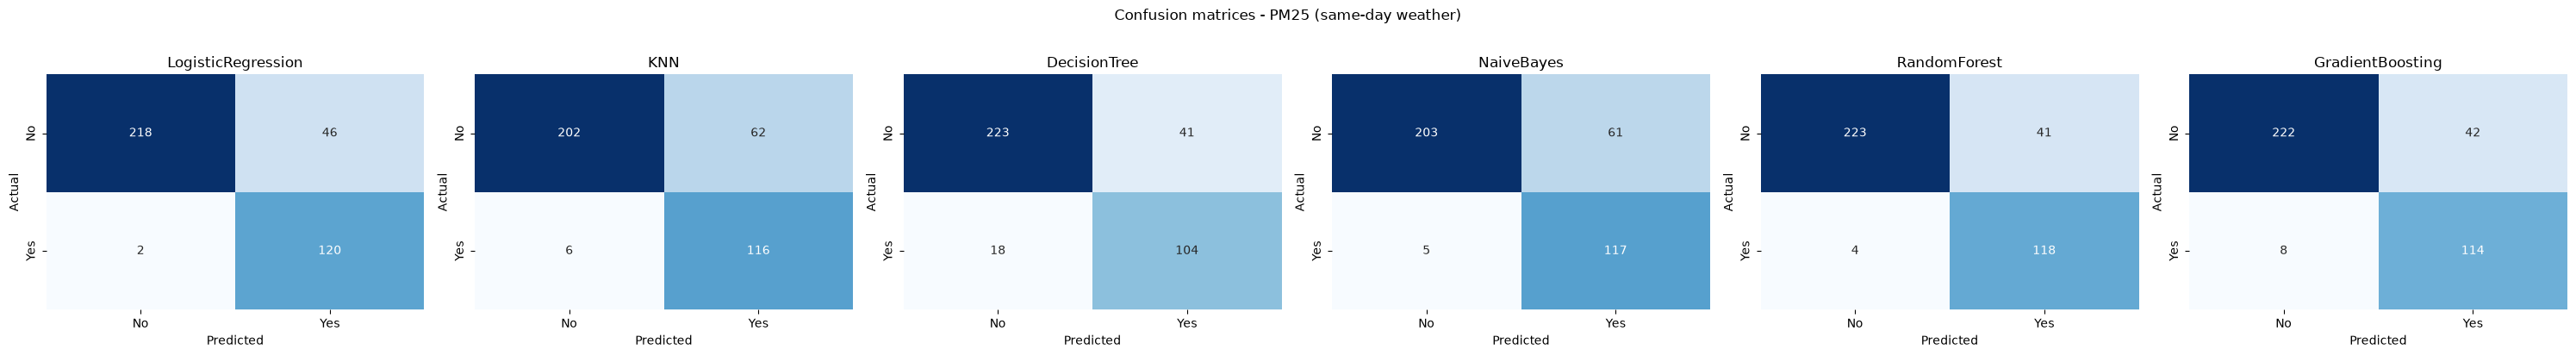

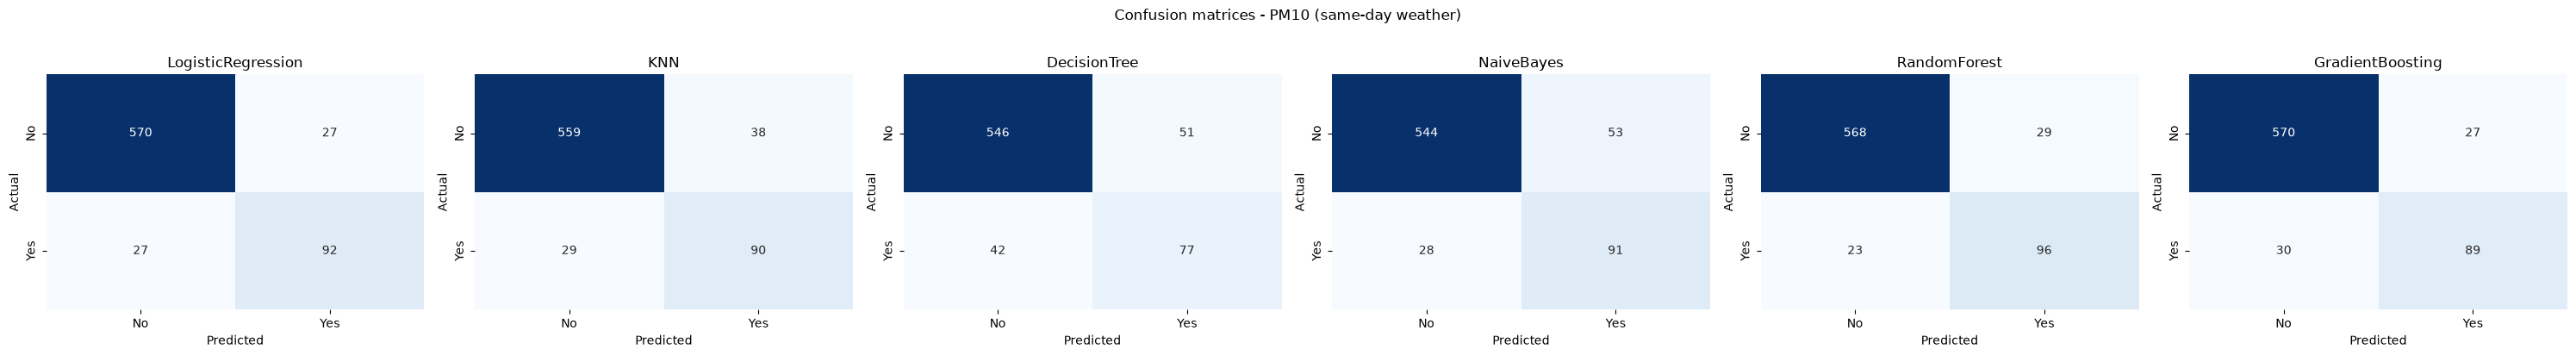

In [14]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]

    fig, axes = plt.subplots(1, len(entry["models"]), figsize=(5 * len(entry["models"]), 4))

    for ax, (name, (model, _, _)) in zip(axes, entry["models"].items()):
        cm = confusion_matrix(entry["y_test"], entry["predictions"][name])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                    xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
        ax.set_title(f"{name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    plt.suptitle(f"Confusion matrices - {pollutant.upper()} (same-day weather)", y=1.02)
    plt.tight_layout()
    plt.show()


In [15]:
comparisons = {}

for pollutant in POLLUTANTS:
    for weather_mode in WEATHER_MODES:
        entry = data[(pollutant, weather_mode)]
        split_idx = entry["split_idx"]

        comparison = pd.DataFrame({"date": entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True),
                                   "station_id": entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True),
                                   "y_test": entry["y_test"].reset_index(drop=True)})

        for name in entry["models"]:
            comparison[name + "_pred"] = entry["predictions"][name]
            comparison[name + "_proba"] = entry["probabilities"][name]

        comparisons[(pollutant, weather_mode)] = comparison

        best_cls = results_by_key[(pollutant, weather_mode)].drop(index="MajorityClass")["F1"].idxmax()
        entry["best_cls"] = best_cls

        print(f"\n{pollutant.upper()} [{weather_mode}]: best classifier by F1 = {best_cls}")

    display(comparisons[(pollutant, "same_day")].head(10))



PM25 [same_day]: best classifier by F1 = RandomForest

PM25 [t_minus_1]: best classifier by F1 = RandomForest


,date,station_id,y_test,LogisticRegression_pred,LogisticRegression_proba,KNN_pred,KNN_proba,DecisionTree_pred,DecisionTree_proba,NaiveBayes_pred,NaiveBayes_proba,RandomForest_pred,RandomForest_proba,GradientBoosting_pred,GradientBoosting_proba
0,2024-07-19,2919,0,0,0.073461,0,0.2,0,0.0,0,2.867869e-17,0,0.036667,0,0.019095
1,2024-07-19,2976,0,0,0.109921,0,0.2,0,0.0,0,5.376219e-17,0,0.160000,0,0.109748
2,2024-07-19,2977,0,0,0.063210,0,0.2,0,0.0,0,2.418301e-17,0,0.023333,0,0.015522
3,2024-07-19,2996,0,0,0.082148,0,0.2,0,0.0,0,3.351545e-17,0,0.050000,0,0.019095
4,2024-07-19,2978,0,0,0.057107,0,0.2,0,0.0,0,2.320850e-17,0,0.020000,0,0.015522
5,2024-07-20,2976,0,0,0.076290,0,0.0,0,0.0,0,4.998581e-16,0,0.143333,0,0.094868
6,2024-07-20,2919,0,0,0.056430,0,0.0,0,0.0,0,2.662794e-16,0,0.033333,0,0.047169
7,2024-07-20,2996,0,0,0.067420,0,0.0,0,0.0,0,3.312391e-16,0,0.070000,0,0.032447
8,2024-07-20,2977,0,0,0.056260,0,0.0,0,0.0,0,2.331403e-16,0,0.020000,0,0.044293
9,2024-07-20,2978,0,0,0.041923,0,0.0,0,0.0,0,1.907735e-16,0,0.020000,0,0.037111



PM10 [same_day]: best classifier by F1 = RandomForest

PM10 [t_minus_1]: best classifier by F1 = RandomForest


,date,station_id,y_test,LogisticRegression_pred,LogisticRegression_proba,KNN_pred,KNN_proba,DecisionTree_pred,DecisionTree_proba,NaiveBayes_pred,NaiveBayes_proba,RandomForest_pred,RandomForest_proba,GradientBoosting_pred,GradientBoosting_proba
0,2024-03-07,2919,0,0,0.129101,0,0.066667,0,0.0,1,0.778242,0,0.036667,0,0.033635
1,2024-03-07,2976,0,0,0.246869,0,0.200000,0,0.0,1,0.866575,0,0.103333,0,0.084359
2,2024-03-07,2979,0,0,0.176367,0,0.133333,0,0.0,1,0.811011,0,0.073333,0,0.054376
3,2024-03-08,2919,0,0,0.059991,1,0.533333,0,0.0,1,0.850994,0,0.206667,0,0.037224
4,2024-03-08,2979,0,0,0.096505,1,0.533333,0,0.0,1,0.863420,0,0.260000,0,0.045461
5,2024-03-08,2976,0,0,0.133895,1,0.600000,0,0.0,1,0.906956,0,0.306667,0,0.081422
6,2024-03-09,2976,0,0,0.431174,0,0.333333,0,0.0,1,0.962539,0,0.296667,0,0.141808
7,2024-03-09,2919,0,0,0.239652,0,0.266667,0,0.0,1,0.937718,0,0.206667,0,0.058096
8,2024-03-09,2979,0,0,0.348609,0,0.266667,0,0.0,1,0.937751,0,0.236667,0,0.088772
9,2024-03-10,2919,0,0,0.049704,0,0.200000,0,0.0,0,0.064553,0,0.116667,0,0.029339


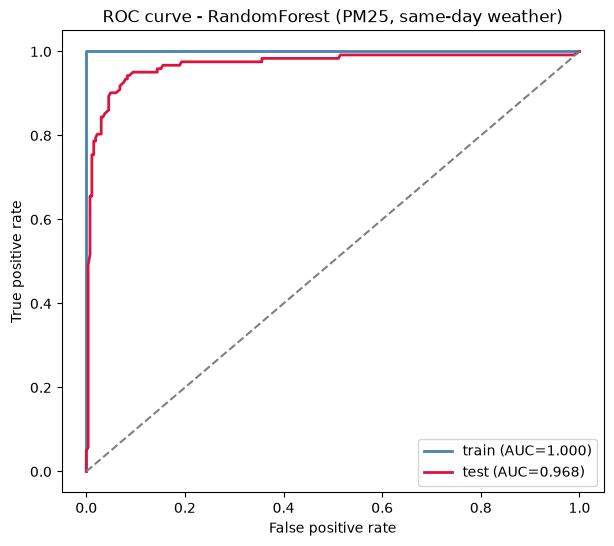

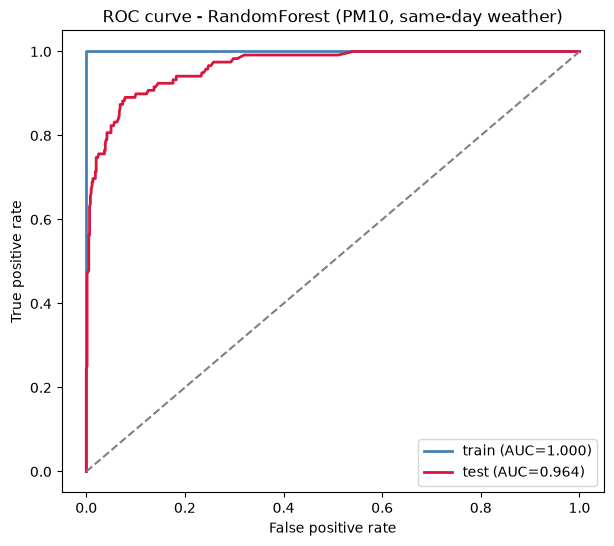

In [16]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    best_cls = entry["best_cls"]
    model, xtr, _ = entry["models"][best_cls]

    proba_train = model.predict_proba(xtr)[:, 1]
    proba_test = entry["probabilities"][best_cls]

    _, ax = plt.subplots(figsize=(7, 6))
    for label, proba, y_true, color in [("train", proba_train, entry["y_train"], "steelblue"),
                                        ("test", proba_test, entry["y_test"], "crimson")]:
        fpr, tpr, _ = roc_curve(y_true, proba)
        ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_true, proba):.3f})",
                color=color, linewidth=2)

    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curve - {best_cls} ({pollutant.upper()}, same-day weather)")
    ax.legend()
    plt.show()



PM25 (RandomForest, same-day weather)


,feature,importance
0,pm25_lag_1,0.143471
4,pm25_rolling_7,0.099825
3,pm25_rolling_3,0.061871
6,pm25_rolling_std_7,0.048162
1,pm25_lag_2,0.040957
2,pm25_lag_3,0.032693
5,pm25_rolling_std_3,0.027915
48,soil_temperature_0_to_7cm_mean,0.022746
55,soil_moisture_100_to_255cm_mean,0.022499
32,diffuse_radiation_sum,0.021045


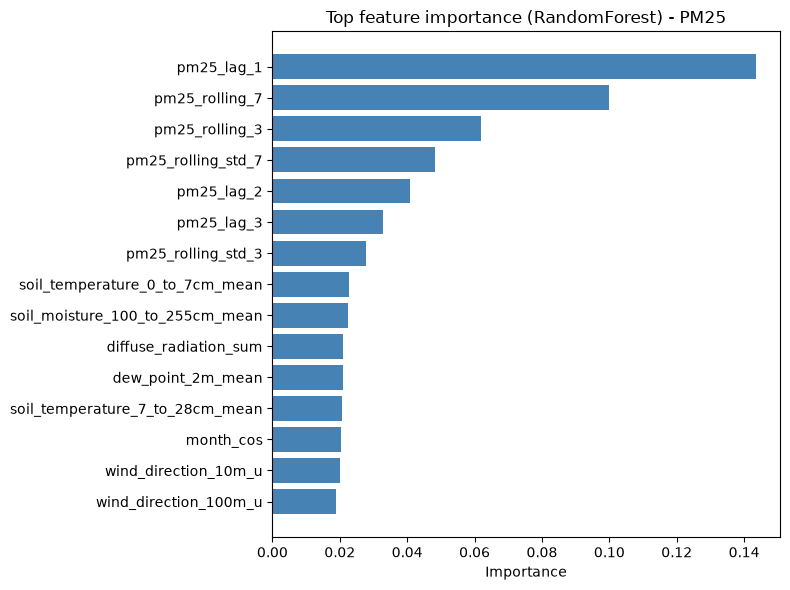


PM10 (RandomForest, same-day weather)


,feature,importance
0,pm10_lag_1,0.132117
3,pm10_rolling_3,0.068711
4,pm10_rolling_7,0.067860
1,pm10_lag_2,0.043063
48,soil_temperature_0_to_7cm_mean,0.040927
39,wind_gusts_10m_max,0.035431
6,pm10_rolling_std_7,0.035158
49,soil_temperature_7_to_28cm_mean,0.033578
2,pm10_lag_3,0.029067
32,diffuse_radiation_sum,0.024107


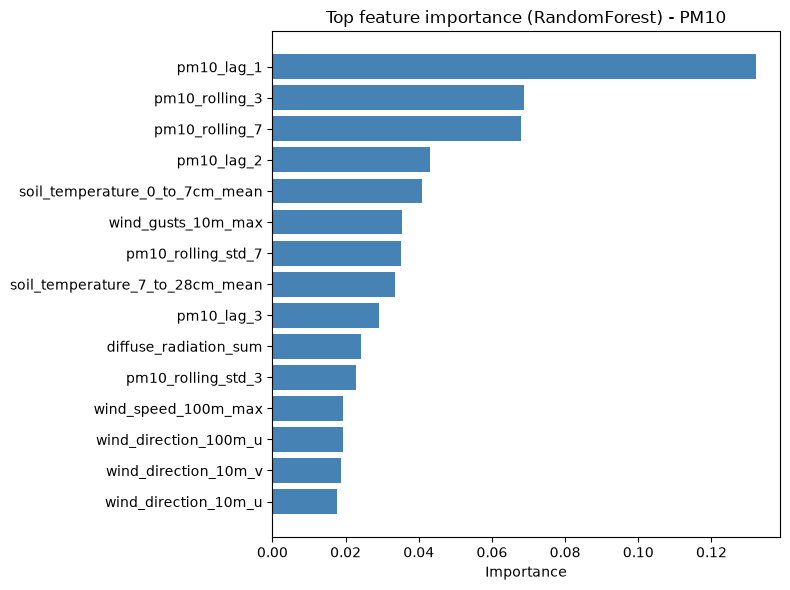

In [17]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    best_cls_model = entry["models"][entry["best_cls"]][0]

    if hasattr(best_cls_model, "feature_importances_"):
        importance = best_cls_model.feature_importances_
    elif hasattr(best_cls_model, "coef_"):
        importance = np.abs(best_cls_model.coef_)
    else:
        print(f"\n{pollutant.upper()} ({entry['best_cls']}): no native feature importance - skipping importance analysis")
        continue

    entry["importance"] = importance

    imp_df = pd.DataFrame({"feature": entry["X"].columns, "importance": importance}).sort_values("importance", ascending=False)

    print(f"\n{pollutant.upper()} ({entry['best_cls']}, same-day weather)")
    display(imp_df.head(15))

    plt.figure(figsize=(8, 6))
    plot_df = imp_df.head(15).iloc[::-1]
    plt.barh(plot_df["feature"], plot_df["importance"], color="steelblue")
    plt.xlabel("Importance")
    plt.title(f"Top feature importance ({entry['best_cls']}) - {pollutant.upper()}")
    plt.tight_layout()
    plt.show()


In [18]:
def get_factor_groups(pollutant, feature_names):
    return {
        "Previous pollution (lag)": [f"{pollutant}_lag_{d}" for d in LAGGED_DAYS],
        "Previous pollution (rolling)": [f"{pollutant}_rolling_{w}" for w in ROLLING_WINDOWS] + [f"{pollutant}_rolling_std_{w}" for w in ROLLING_WINDOWS],
        "Temperature": [c for c in feature_names if "temperature" in c or "dew_point" in c],
        "Humidity": [c for c in feature_names if "humidity" in c or "vapour_pressure" in c],
        "Wind": [c for c in feature_names if "wind" in c and "category" not in c] + [c for c in feature_names if c.startswith("wind_")],
        "Precipitation": [c for c in feature_names if "precip" in c or "rain" in c or "snowfall" in c or "snow_depth" in c],
        "Pressure": [c for c in feature_names if "pressure" in c],
        "Clouds & radiation": [c for c in feature_names if "cloud" in c or "radiation" in c or "sunshine" in c or "et0" in c],
        "Season / calendar": [c for c in feature_names if "month" in c or "dow" in c or "weekend" in c],
        "Soil": [c for c in feature_names if c.startswith("soil")],
        "Wind category": [c for c in feature_names if c.startswith("wind_weak") or c.startswith("wind_moderate") or c.startswith("wind_strong")],
        "Weather code": [c for c in feature_names if "weather_code" in c],
    }


In [19]:
def group_importance(importance, feature_names, factor_groups):
    factor_importance = []

    for factor, cols in factor_groups.items():
        present = [c for c in cols if c in feature_names]
        if not present:
            continue

        vals = [importance[feature_names.index(c)] for c in present]
        factor_importance.append({
            "factor": factor,
            "n_features": len(present),
            "importance_max": float(np.max(vals)),
            "importance_mean": float(np.mean(vals)),
        })

    return pd.DataFrame(factor_importance).sort_values("importance_mean", ascending=False)


In [20]:
factor_tables = {}

for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    if "importance" not in entry:
        continue

    feature_names = list(entry["X"].columns)
    factor_df = group_importance(entry["importance"], feature_names, get_factor_groups(pollutant, feature_names))
    factor_tables[pollutant] = factor_df

    print(f"\n{pollutant.upper()} ({entry['best_cls']})")
    display(factor_df.round(4))



PM25 (RandomForest)


,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.1435,0.0724
1,Previous pollution (rolling),4,0.0998,0.0594
9,Soil,8,0.0227,0.0158
2,Temperature,9,0.0227,0.0150
7,Clouds & radiation,9,0.0210,0.0120
4,Wind,24,0.0200,0.0096
3,Humidity,4,0.0089,0.0083
6,Pressure,5,0.0091,0.0083
8,Season / calendar,5,0.0203,0.0060
5,Precipitation,5,0.0074,0.0034



PM10 (RandomForest)


,factor,n_features,importance_max,importance_mean
0,Previous pollution (lag),3,0.1321,0.0681
1,Previous pollution (rolling),4,0.0687,0.0486
2,Temperature,9,0.0409,0.0177
9,Soil,8,0.0409,0.0161
4,Wind,24,0.0354,0.0138
7,Clouds & radiation,9,0.0241,0.0124
6,Pressure,5,0.0095,0.0090
3,Humidity,4,0.0092,0.0076
8,Season / calendar,5,0.0138,0.0048
5,Precipitation,5,0.0082,0.0047


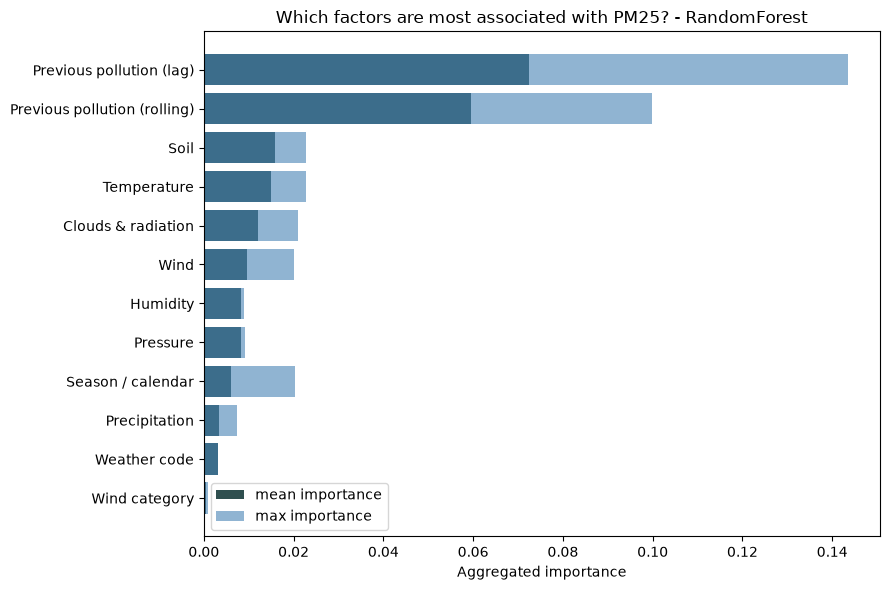

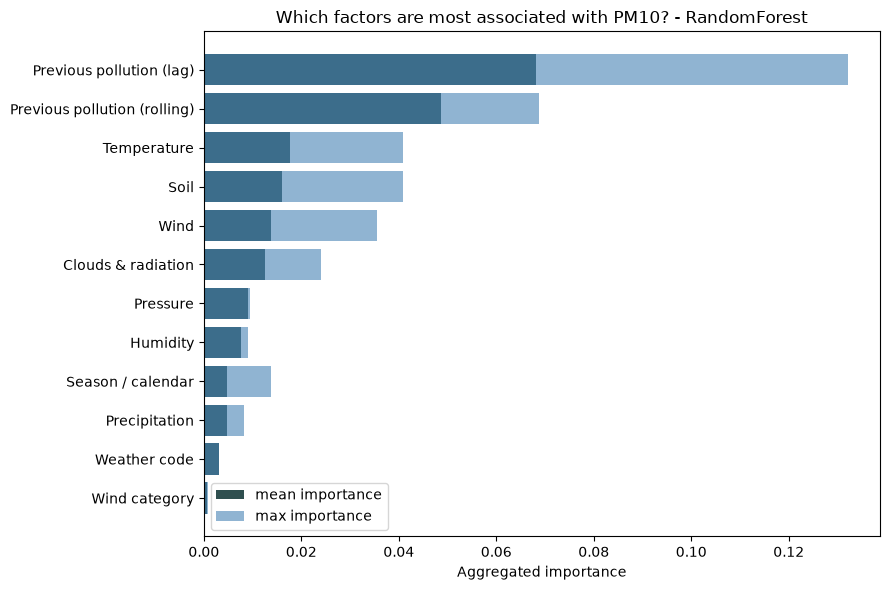

In [21]:
for pollutant in POLLUTANTS:
    if pollutant not in factor_tables:
        continue

    entry = data[(pollutant, "same_day")]
    factor_df = factor_tables[pollutant]

    plt.figure(figsize=(9, 6))
    plot_df = factor_df.iloc[::-1]
    plt.barh(plot_df["factor"], plot_df["importance_mean"], color="darkslategray", label="mean importance")
    plt.barh(plot_df["factor"], plot_df["importance_max"], color="steelblue", alpha=0.6, label="max importance")
    plt.xlabel("Aggregated importance")
    plt.title(f"Which factors are most associated with {pollutant.upper()}? - {entry['best_cls']}")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [22]:
for pollutant in POLLUTANTS:
    entry = data[(pollutant, "same_day")]
    split_idx = entry["split_idx"]

    METRICS_OUT = PROCESSED_DIR / f"classification_metrics_{pollutant}.parquet"
    PRED_OUT = PROCESSED_DIR / f"classification_predictions_{pollutant}.parquet"
    PROBA_OUT = PROCESSED_DIR / f"classification_probabilities_{pollutant}.parquet"

    results_by_key[(pollutant, "same_day")].to_parquet(METRICS_OUT)
    comparisons[(pollutant, "same_day")].to_parquet(PRED_OUT, index=False)

    proba_df = pd.DataFrame(entry["probabilities"])
    proba_df["date"] = entry["model_df"]["date"].iloc[split_idx:].reset_index(drop=True)
    proba_df["station_id"] = entry["model_df"]["station_id"].iloc[split_idx:].reset_index(drop=True)
    proba_df.to_parquet(PROBA_OUT, index=False)

    print(f"Saved: {METRICS_OUT.name} (same_day weather variant)")
    print(f"Saved: {PRED_OUT.name} (same_day weather variant)")
    print(f"Saved: {PROBA_OUT.name} (same_day weather variant)")


Saved: classification_metrics_pm25.parquet (same_day weather variant)
Saved: classification_predictions_pm25.parquet (same_day weather variant)
Saved: classification_probabilities_pm25.parquet (same_day weather variant)
Saved: classification_metrics_pm10.parquet (same_day weather variant)
Saved: classification_predictions_pm10.parquet (same_day weather variant)
Saved: classification_probabilities_pm10.parquet (same_day weather variant)
